# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3383 Злобин Иван Владимирович. Вариант №12.

## Цель работы
Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

### Линейная дискретная система

Передаточная функция причинного рекурсивного звена второго порядка и соответствующее разностное уравнение при $a_0=1$:
$$
H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}},
$$
$$
y[n]=b_0x[n]+b_1x[n-1]+b_2x[n-2]-a_1y[n-1]-a_2y[n-2].
$$
При нулевых начальных условиях $x[n]=y[n]=0$ для $n<0$. 

Импульсная характеристика - это реакция на единичный дискретный импульс $\delta[n]$. 

Реакция на произвольное воздействие определяется свёрткой:
$$
y[n]=\sum_{m=-\infty}^{\infty}h[m]x[n-m].
$$
Для двух конечных массивов длины $L$ и $M$ полная линейная свёртка содержит $L+M-1$ отсчётов; крайние отсчёты могут оказаться нулевыми. Причинная рациональная система устойчива по ограниченному входу и выходу, если после сокращений все полюсы находятся внутри единичной окружности. Для такой системы импульсная характеристика абсолютно суммируема.

Частотная характеристика получается подстановкой $z=e^{j\hat\omega}$:
$$
H(e^{j\hat\omega})=\frac{\sum_{m=0}^{2}b_m e^{-j\hat\omega m}}{\sum_{m=0}^{2}a_m e^{-j\hat\omega m}},
\qquad A(\hat\omega)=|H(e^{j\hat\omega})|,\quad
\varphi(\hat\omega)=\arg H(e^{j\hat\omega}).
$$
Здесь $\hat\omega=\omega T=2\pi f/f_d$ нормированная угловая частота, рад/отсчёт. Частотная характеристика периодична по $\hat\omega$ с периодом $2\pi$.

### ДПФ и восстановление сигнала
Используется следующая пара прямого и обратного ДПФ:
$$
X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},
\qquad
x[n]=\frac1N\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.
$$
Для периодического продолжения последовательности коэффициенты комплексного ряда Фурье равны $C[k]=X[k]/N$. В работе амплитудный спектр периодической последовательности определяется как двусторонний спектр $|C[k]|=|X[k]|/N$, а фазовый $\arg C[k]$. В одностороннем представлении амплитуды положительных гармоник вещественного сигнала удваиваются, кроме постоянной составляющей и частоты Найквиста.

Приняты обозначения:
$$
t_n=nT,\qquad \hat t_n=t_n/T=n,\qquad
\nu_k=k/N,\qquad \hat\omega_k=2\pi\nu_k,\qquad f_k=\nu_k f_d.
$$
Таким образом, $\nu$ измеряется в циклах/отсчёт, а $\hat\omega$ в рад/отсчёт. На центрированных спектрах используются отрицательные и положительные частоты. Фаза спектрального отсчёта с нулевой амплитудой не определена.

При отсутствии частот выше $f_d/2$ тригонометрический полином по отсчётам ДПФ восстанавливает исходный периодический сигнал. 

Равенство Парсеваля для выбранной нормировки:
$$
\sum_{n=0}^{N-1}|x[n]|^2=\frac1N\sum_{k=0}^{N-1}|X[k]|^2,
\qquad
\frac{1}{N}\sum_{n=0}^{N-1}|x[n]|^2=\sum_{k=0}^{N-1}|C[k]|^2.
$$

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.


## Выполнение работы


Дополнительные функции для работы.

Для рекурсии используется собственная функция `difference_equation`. Частотная характеристика вычисляется чере суммы экспонент. Нули и полюсы находятся через `np.roots`. ДПФ и ОДПФ с помощью `np.fft`.

In [29]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=8, suppress=True)
plt.rcParams.update({
    'figure.figsize': (11, 4), 'figure.dpi': 110,
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.grid': True, 'grid.alpha': 0.28,
    'axes.spines.top': False, 'axes.spines.right': False,
})

def difference_equation(x, b, a):
    y = np.zeros(len(x), dtype=float)
    for n in range(len(x)):
        input_sum = sum(b[m]*x[n-m] for m in range(len(b)) if n-m >= 0)
        feedback = sum(a[k]*y[n-k] for k in range(1, len(a)) if n-k >= 0)
        y[n] = (input_sum - feedback)/a[0]
    return y

def frequency_response(b, a, omega):
    numerator = np.exp(-1j*np.outer(omega, np.arange(len(b)))) @ b
    denominator = np.exp(-1j*np.outer(omega, np.arange(len(a)))) @ a
    return numerator/denominator

def stem(ax, x, y, title, xlabel, ylabel, color='C0'):
    marker, lines, baseline = ax.stem(x, y, basefmt=' ', linefmt=color+'-', markerfmt=color+'o')
    plt.setp(marker, markersize=3)
    plt.setp(lines, linewidth=1)
    ax.axhline(0, color='0.5', linewidth=0.6)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)

### Часть 1

#### Параметры варианта

In [30]:

Nvar = 12
b0 = 0.5 + 0.02 * Nvar
b1 = b0 * (-1)**(Nvar + 1) * (0.9822 + 0.0178 * Nvar)
b2 = b0 * (0.8 + 0.2 * (Nvar % 5))
a0 = 1
a1 = (-1)**Nvar * (0.7778 + 0.025 * Nvar)
a2 = 0.64 + 0.006 * Nvar
N1 = Nvar % 10 + 20
N2 = Nvar % 10 + 30
fd = 1000 * Nvar
b = np.array([b0, b1, b2])
a = np.array([a0, a1, a2])

| Параметр | Значение |
| :--- | :--- |
| Вариант | 12 |
| $b_0, b_1, b_2$ | 0.740000, -0.884892, 0.888000 |
| $a_0, a_1, a_2$ | 1.000000, 1.077800, 0.712000 |
| $N_1$ | 22 |
| $N_2$ | 32 |
| $f_d$, Гц | 12000 |

#### 1. Импульсная характеристика
Передаточная функция:
$$
H(z)=\frac{0.74-0.884892z^{-1}+0.888z^{-2}}
{1+1.0778z^{-1}+0.712z^{-2}}.
$$
Единичный импульс задаётся как $\delta[0]=1$, $\delta[n]=0$ при $n\ne 0$. Вычислим первые $N_1=22$ отсчёта реакции при нулевом состоянии.

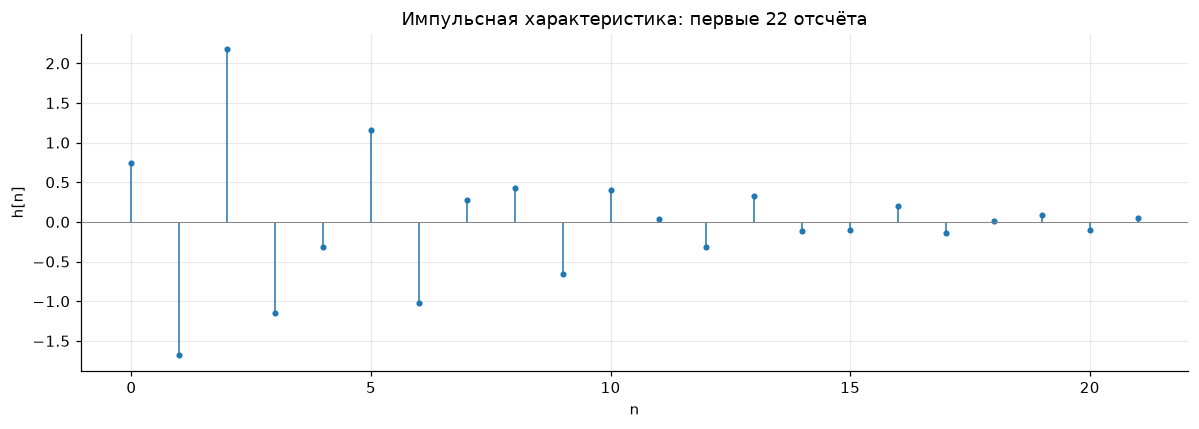

In [31]:
delta = np.zeros(N1)
delta[0] = 1.0
h = difference_equation(delta, b, a)  # Начальное состояние нулевое.
fig, ax = plt.subplots()
stem(ax, np.arange(N1), h, 'Импульсная характеристика: первые 22 отсчёта', 'n', 'h[n]')
fig.tight_layout()
plt.show()

| $n$ | $h[n]$ |
| :--- | :--- |
| 0 | 0.740000000 |
| 1 | -1.682464000 |
| 2 | 2.174479699 |
| 3 | -1.145739852 |
| 4 | -0.313351134 |
| 5 | 1.153496626 |
| 6 | -1.020132657 |
| 7 | 0.278209379 |
| 8 | 0.426480382 |
| 9 | -0.657745634 |
| 10 | 0.405264212 |
| 11 | 0.031521123 |
| 12 | -0.322521586 |
| 13 | 0.325170726 |
| 14 | -0.120833639 |
| 15 | -0.101287061 |
| 16 | 0.195200745 |
| 17 | -0.138270976 |
| 18 | 0.010045527 |
| 19 | 0.087621866 |
| 20 | -0.101591262 |
| 21 | 0.047108294 |

Аналитическая формула. 
Полюсы знаменателя имеют вид $p_{1,2}=re^{\pm j\theta}$, где
$$
r=\sqrt{0.712}\approx 0.843800924, 
\qquad
\theta=\arccos\left(\frac{-1.0778}{2r}\right)\approx 0.720510022\pi.
$$
Определим последовательность
$$
g[n]=\begin{cases}
\displaystyle r^n\frac{\sin((n+1)\theta)}{\sin\theta}, & n\ge 0,\\
0, & n<0.
\end{cases}
$$
Это импульсная характеристика звена $1/(1+1.0778z^{-1}+0.712z^{-2})$. Поэтому искомая формула, учитывающая нулевые начальные условия:
$$
h[n]=0.74g[n]-0.884892g[n-1]+0.888g[n-2].
$$

Длина рассчитанного отрезка равна 22, но действительная импульсная характеристика имеет бесконечную длину, так как полюсы не сокращаются нулями, и рекурсия создаёт затухающие колебания, множитель $r^n$ стремится к нулю.

#### 2. Реакция по формуле свёртки

$$
x[n]=\begin{cases}1,&0\le n<16,\\0,&16\le n\le31.\end{cases}
$$
Длина массива воздействия 32 отсчёта, ширина его ненулевой части 16 отсчётов.

Для вычисленной импульсной характеристики $h_{22}[m]$:
$$
y_1[n]=\sum_{m=0}^{21}h[m]x[n-m],\qquad x[n]=0\quad(n<0\;\text{or}\;n>31).
$$
Вычислим полную линейную свёртку и её начальный отрезок длины воздействия.

Длина массива x: 32; ширина импульса: 16
Длина полной свёртки: 53 = 22 + 32 - 1
Последний ненулевой отсчёт полной свёртки: n = 36
Длина оставленного отрезка y1: 32


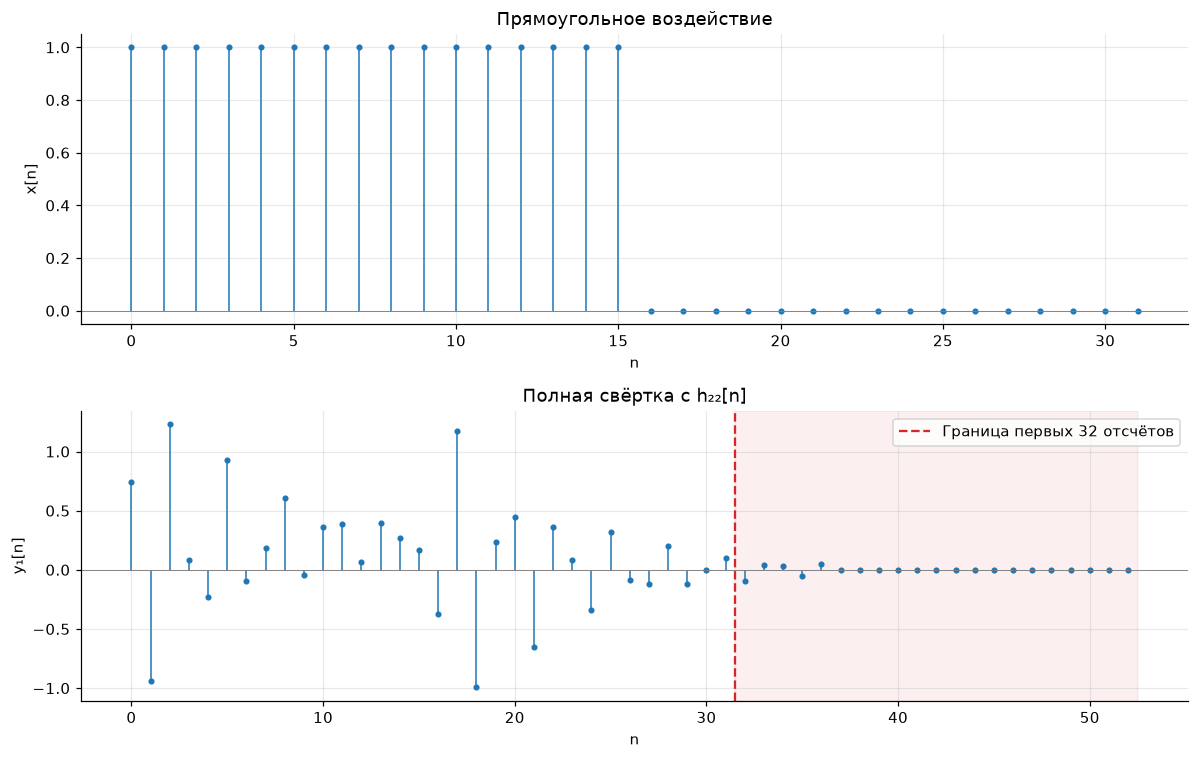

In [32]:
n_x = np.arange(N2)
pulse_width = int(np.rint(N2/2))
x_rect = (n_x < pulse_width).astype(float)
y1_full = np.convolve(x_rect, h, mode='full')
y1 = y1_full[:N2]
nonzero_y1 = np.flatnonzero(np.abs(y1_full) > 1e-12)
print(f'Длина массива x: {len(x_rect)}; ширина импульса: {pulse_width}')
print(f'Длина полной свёртки: {len(y1_full)} = {N1} + {N2} - 1')
print(f'Последний ненулевой отсчёт полной свёртки: n = {nonzero_y1[-1]}')
print(f'Длина оставленного отрезка y1: {len(y1)}')

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
stem(axes[0], n_x, x_rect, 'Прямоугольное воздействие', 'n', 'x[n]')
stem(axes[1], np.arange(len(y1_full)), y1_full, 'Полная свёртка с h₂₂[n]', 'n', 'y₁[n]')
axes[1].axvline(N2-0.5, color='C3', linestyle='--', label='Граница первых 32 отсчётов')
axes[1].axvspan(N2-0.5, len(y1_full)-0.5, color='C3', alpha=0.07)
axes[1].legend()
fig.tight_layout()
plt.show()

Для массивов длины 22 и 32 результат содержит $22+32-1=53$ отсчёта, с индексами $0,\ldots,52$. Последние 16 отсчётов входного массива нулевые, поэтому ненулевая часть результата заканчивается на $n=15+21=36$ и занимает 37 отсчётов. Нулевые точки $n=37,\ldots,52$ также входят в полный массив свёртки.

Ограничение до первых 32 отсчётов выбирает тот же интервал наблюдения, что у входа, и позволяет сопоставить результат с вызовом фильтра на массиве длины 32.

#### 3. Реакция по разностному уравнению

Разностное уравнение:
$$
y_2[n]=0.74x[n]-0.884892x[n-1]+0.888x[n-2]-1.0778y_2[n-1]-0.712y_2[n-2].
$$
Начальные условия: $x[-1]=x[-2]=y_2[-1]=y_2[-2]=0$. Выполним рекурсию явно и сравним результат со свёрткой. Для изображения хвоста после $n=31$ продолжим вход нулями.

Свёртка с h длины 32 и рекурсия, n=0…31: 3.331e-16
Свёртка с h длины 22 и рекурсия, n=0…31: 0.035218447


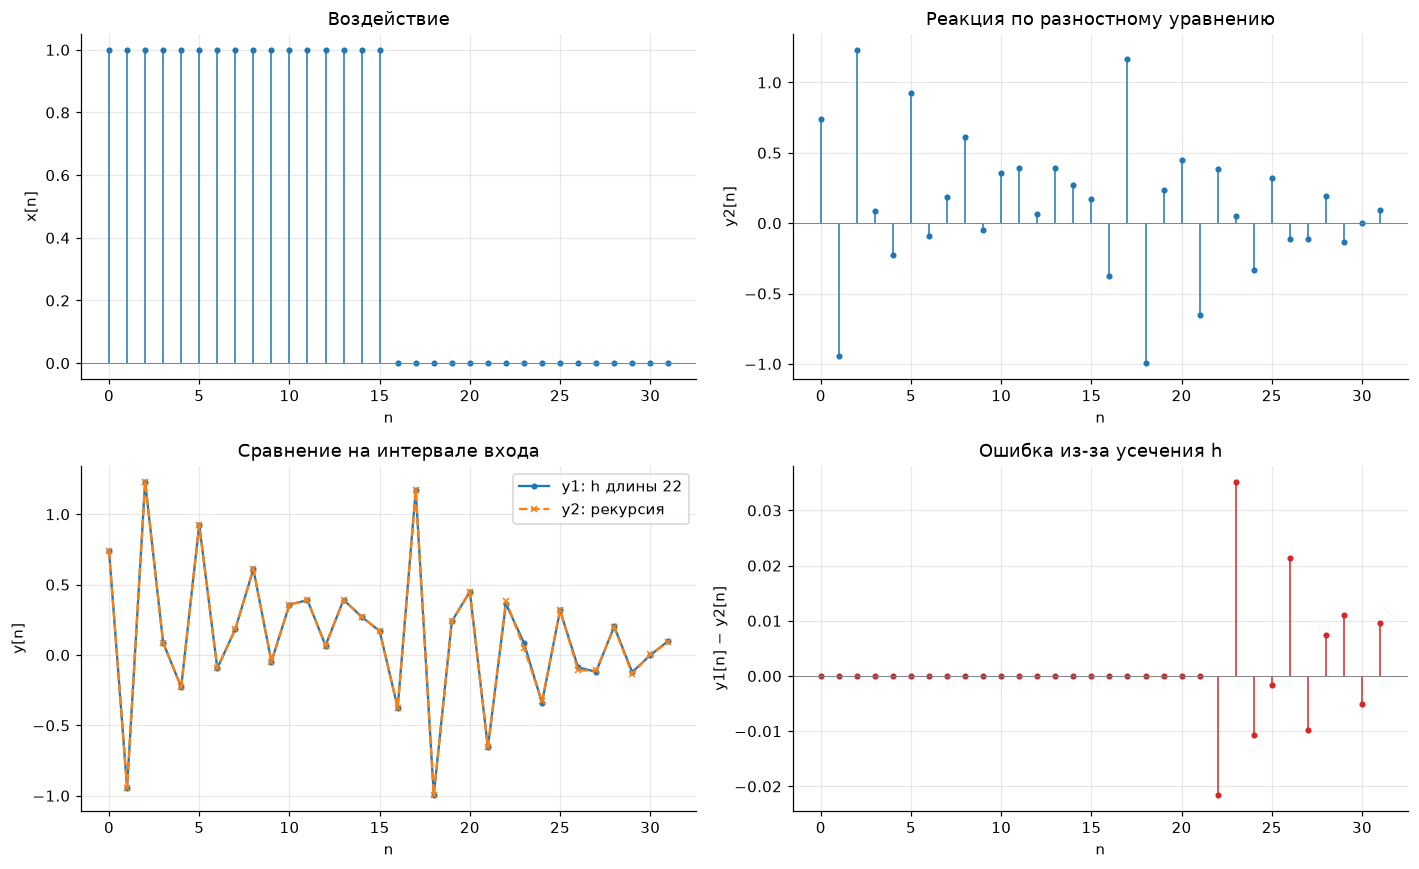

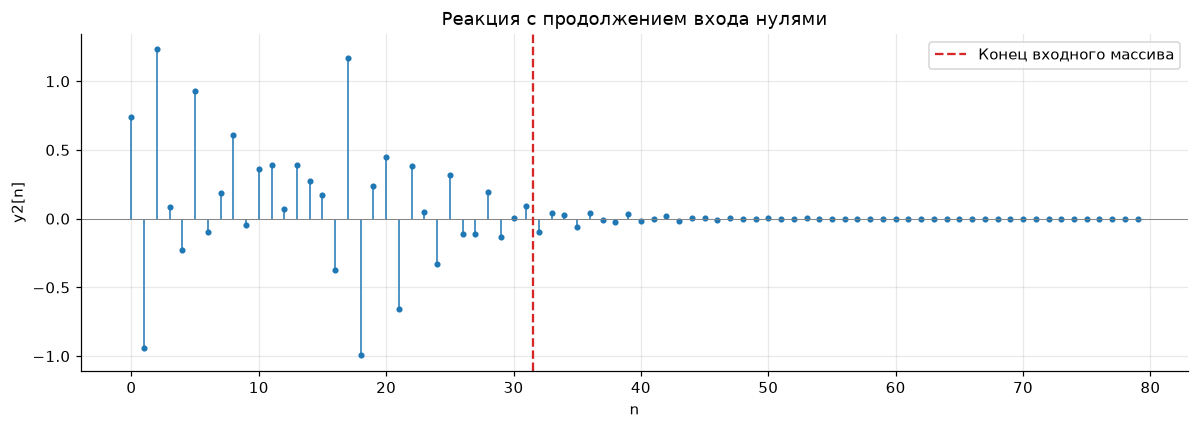

In [33]:
y2 = difference_equation(x_rect, b, a)
delta32 = np.zeros(N2)
delta32[0] = 1.0
h32 = difference_equation(delta32, b, a)
y_conv32 = np.convolve(x_rect, h32)[:N2]
y2_tail = difference_equation(np.pad(x_rect, (0, 128-N2)), b, a)

err_methods = np.max(np.abs(y_conv32-y2))
err_truncation = np.max(np.abs(y1-y2))
print(f'Свёртка с h длины 32 и рекурсия, n=0…31: {err_methods:.3e}')
print(f'Свёртка с h длины 22 и рекурсия, n=0…31: {err_truncation:.9f}')

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
stem(axes[0,0], n_x, x_rect, 'Воздействие', 'n', 'x[n]')
stem(axes[0,1], n_x, y2, 'Реакция по разностному уравнению', 'n', 'y2[n]')
axes[1,0].plot(n_x, y1, 'o-', ms=3, label='y1: h длины 22')
axes[1,0].plot(n_x, y2, 'x--', ms=4, label='y2: рекурсия')
axes[1,0].set(title='Сравнение на интервале входа', xlabel='n', ylabel='y[n]')
axes[1,0].legend()
stem(axes[1,1], n_x, y1-y2, 'Ошибка из-за усечения h', 'n', 'y1[n] − y2[n]', color='C3')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots()
stem(ax, np.arange(80), y2_tail[:80], 'Реакция с продолжением входа нулями', 'n', 'y2[n]')
ax.axvline(N2-0.5, color='C3', ls='--', label='Конец входного массива')
ax.legend()
fig.tight_layout()
plt.show()


На интервале $0\le n\le21$ значения $y_1$ и $y_2$ совпадают с точностью вычислений. Далее во входной свёртке начинают участвовать отсутствующие отсчёты $h[22],h[23],\ldots$; максимальное расхождение на $0\le n\le31$ составляет примерно $0.035218447$. Если взять 32 отсчёта импульсной характеристики, свёртка и рекурсия на этом интервале совпадают с машинной точностью.

При одинаковой полной импульсной характеристике оба метода эквивалентны. Различие в выполненном расчёте обусловлено заданным усечением до $N_1=22$. Длина входного массива равна 32, ненулевая часть 16, а длина возвращённого массива равна 32. Теоретическая реакция рекурсивного звена при продолжении входа нулями имеет бесконечный затухающий хвост.

#### 4. Нули и полюсы передаточной функции
Умножение числителя и знаменателя на $z^2$ даёт:
$$
H(z)=\frac{0.74z^2-0.884892z+0.888}{z^2+1.0778z+0.712}.
$$
Нули - это корни числителя. Полюсы - это корни знаменателя. Для комплексного числа $v=\alpha+j\beta$ алгебраическая и показательная формы связаны соотношениями
$$
v=\alpha+j\beta=\rho e^{j\phi},
\qquad
\rho=\sqrt{\alpha^2+\beta^2},\qquad\phi=\operatorname{atan2}(\beta,\alpha).
$$

Вычисление корней обоих полиномов выполняется функцией `np.roots`.

In [34]:
zeros = np.roots(b)
poles = np.roots(a)
gain = b[0]/a[0]

def complex_str(v):
    return f'{v.real:.9f} {"+" if v.imag >= 0 else "−"} j{abs(v.imag):.9f}'

rows=[]
for kind, values in [('Нуль', zeros), ('Полюс', poles)]:
    for i, v in enumerate(sorted(values, key=lambda z: z.imag, reverse=True), 1):
        rows.append([f'{kind} {i}', complex_str(v), f'{abs(v):.9f}',
                     f'{np.angle(v):.9f}', f'{np.angle(v)/np.pi:.9f}π',
                     f'{abs(v):.9f} exp(j·({np.angle(v)/np.pi:.9f}π))'])
print(f'Множитель усиления: {gain:.6f}')
print(f'Невязка числителя в нулях: {np.max(np.abs(np.polyval(b, zeros))):.3e}')
print(f'Невязка знаменателя в полюсах: {np.max(np.abs(np.polyval(a, poles))):.3e}')

Множитель усиления: 0.740000
Невязка числителя в нулях: 2.245e-16
Невязка знаменателя в полюсах: 1.831e-16


| Корень | Алгебраическая форма | Модуль | Аргумент, рад | Аргумент / $\pi$ | Показательная форма |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Нуль 1 | $0.597900000 + j0.917886480$ | 1.095445115 | 0.993446160 | 0.316223734 | $1.095445115e^{j0.316223734\pi}$ |
| Нуль 2 | $0.597900000 - j0.917886480$ | 1.095445115 | -0.993446160 | -0.316223734 | $1.095445115e^{-j0.316223734\pi}$ |
| Полюс 1 | $-0.538900000 + j0.649297151$ | 0.843800924 | 2.263548992 | 0.720510022 | $0.843800924e^{j0.720510022\pi}$ |
| Полюс 2 | $-0.538900000 - j0.649297151$ | 0.843800924 | -2.263548992 | -0.720510022 | $0.843800924e^{-j0.720510022\pi}$ |

С округлением корней:
$$
z_{1,2}=0.5979\pm j0.917886480
=1.095445115e^{\pm j0.316223734\pi},
$$
$$
p_{1,2}=-0.5389\pm j0.649297151
=0.843800924e^{\pm j0.720510022\pi}.
$$
Коэффициенты передаточной функции вещественные, поэтому комплексные корни образуют сопряжённые пары: их модули одинаковы, а аргументы противоположны. Нули и полюсы между собой не совпадают и не сокращаются.

Передаточная функция в виде произведения простейших множителей:
$$
H(z)=0.74\,
\frac{(1-1.095445115e^{j0.316223734\pi}z^{-1})(1-1.095445115e^{-j0.316223734\pi}z^{-1})}
{(1-0.843800924e^{j0.720510022\pi}z^{-1})(1-0.843800924e^{-j0.720510022\pi}z^{-1})}.
$$
Для причинной системы область сходимости $|z|>0.843800924$ включает единичную окружность.

#### 5. Карта нулей и полюсов

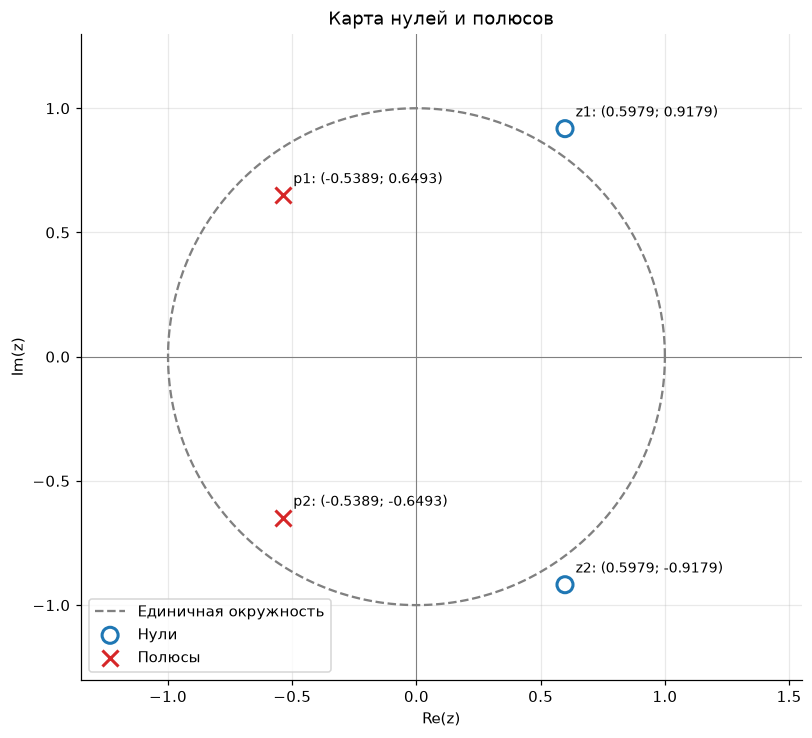

Модули полюсов: [0.84380092 0.84380092]
Устойчивость: True


In [11]:
phi_circle = np.linspace(0, 2*np.pi, 500)
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.plot(np.cos(phi_circle), np.sin(phi_circle), color='0.5', ls='--', label='Единичная окружность')
ax.scatter(zeros.real, zeros.imag, facecolors='none', edgecolors='C0', s=110, linewidths=2, label='Нули')
ax.scatter(poles.real, poles.imag, marker='x', color='C3', s=110, linewidths=2, label='Полюсы')
for name, values in [('z', sorted(zeros, key=lambda v: v.imag, reverse=True)),
                     ('p', sorted(poles, key=lambda v: v.imag, reverse=True))]:
    for i, v in enumerate(values, 1):
        ax.annotate(f'{name}{i}: ({v.real:.4f}; {v.imag:.4f})',
                    (v.real, v.imag), xytext=(7, 8), textcoords='offset points', fontsize=9)
ax.axhline(0, color='0.5', lw=.7)
ax.axvline(0, color='0.5', lw=.7)
ax.set(xlim=(-1.35, 1.55), ylim=(-1.3, 1.3), xlabel='Re(z)', ylabel='Im(z)', title='Карта нулей и полюсов')
ax.set_aspect('equal')
ax.legend(loc='lower left')
fig.tight_layout()
plt.show()
print('Модули полюсов:', np.abs(poles))
print('Устойчивость:', bool(np.all(np.abs(poles) < 1)))


Оба полюса находятся внутри единичной окружности $|p_{1,2}|=0.843800924<1$, поэтому причинное звено устойчиво. Наблюдаемые колебания импульсной характеристики затухают. Нули находятся за единичной окружностью, но положение нулей не нарушает устойчивость этого звена. Координаты отмеченных точек совпадают с корнями из пункта 4.

#### 6. АЧХ и ФЧХ в нормированной шкале

Построим одностороннюю половину основной полосы $0\le\hat\omega\le\pi$. Полная основная полоса может быть выбрана как $-\pi\le\hat\omega<\pi$; её ширина равна $2\pi$. Для вещественных коэффициентов АЧХ чётна, а ФЧХ нечётна с точностью до выбора ветви аргумента.

Сетка включает обе границы: `np.linspace(0, np.pi, 16385)`. Значения частотной характеристики рассчитываются непосредственно по формуле из теоретического раздела.

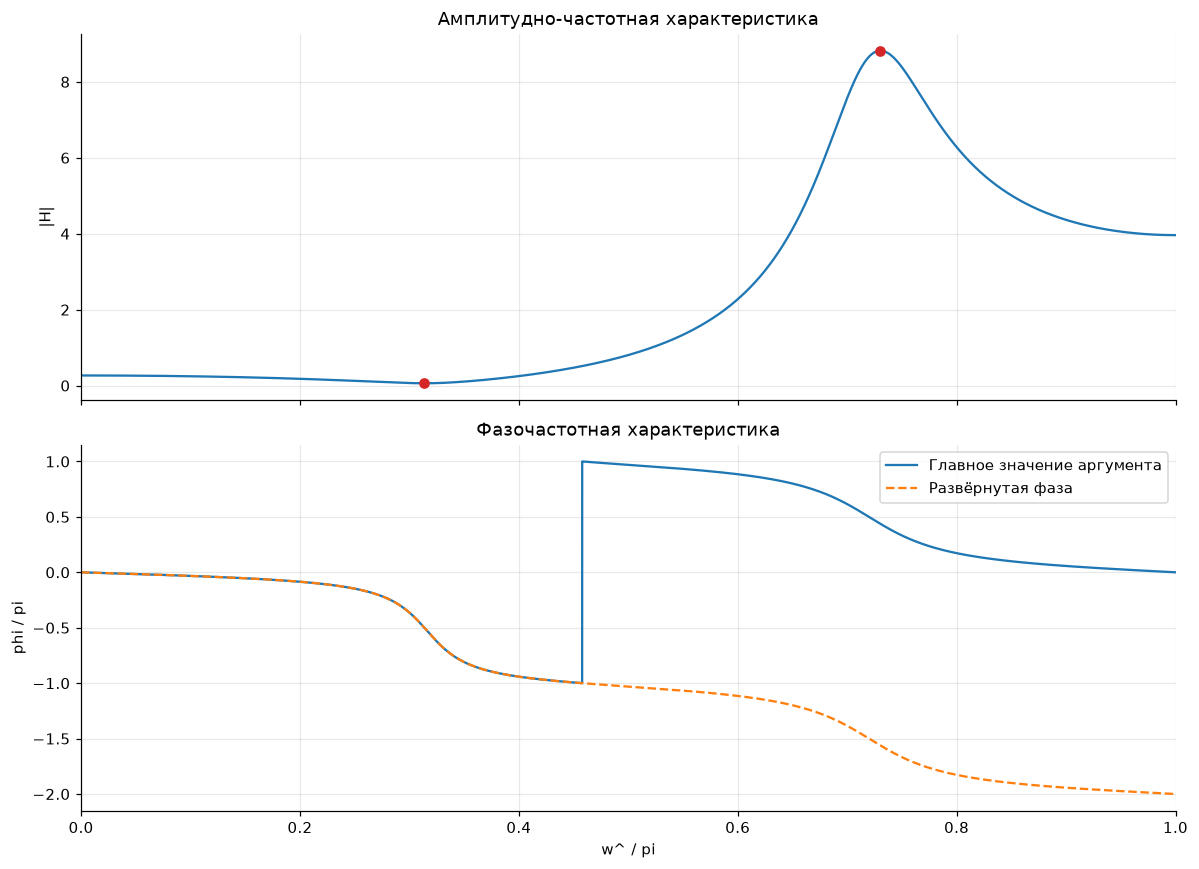

Переход ветви фазы: w^/pi = 0.457855, |H| = 0.513684


In [13]:
w = np.linspace(0, np.pi, 16385)
H = frequency_response(b, a, w)
amp = np.abs(H)
phase_wrapped = np.angle(H)
phase_unwrapped = np.unwrap(phase_wrapped)
i_min, i_max = np.argmin(amp), np.argmax(amp)
jumps = np.flatnonzero(np.abs(np.diff(phase_wrapped)) > np.pi)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
axes[0].plot(w/np.pi, amp)
axes[0].scatter(w[[i_min,i_max]]/np.pi, amp[[i_min,i_max]], color='C3', zorder=3)
axes[0].set(title='Амплитудно-частотная характеристика', ylabel='|H|')
axes[1].plot(w/np.pi, phase_wrapped/np.pi, label='Главное значение аргумента')
axes[1].plot(w/np.pi, phase_unwrapped/np.pi, '--', label='Развёрнутая фаза')
axes[1].set(title='Фазочастотная характеристика', xlabel='w^ / pi', ylabel='phi / pi')
axes[1].set_xlim(0, 1)
axes[1].legend()
fig.tight_layout()
plt.show()
for i in jumps:
    print(f'Переход ветви фазы: w^/pi = {(w[i]+w[i+1])/(2*np.pi):.6f}, |H| = {amp[i]:.6f}')

| Точка | $\hat{\omega}/\pi$ | $\lvert H\rvert$ |
| :--- | :--- | :--- |
| Постоянная составляющая | 0 | 0.266366048 |
| Минимум | 0.313537598 | 0.060954178 |
| Максимум | 0.730407715 | 8.819481264 |
| Частота Найквиста | 1 | 3.962302113 |

На единичной окружности
$$
|H(e^{j\hat\omega})|=0.74
\frac{|e^{j\hat\omega}-z_1|\,|e^{j\hat\omega}-z_2|}
{|e^{j\hat\omega}-p_1|\,|e^{j\hat\omega}-p_2|}.
$$
Вблизи аргумента нуля $0.3162\pi$ числитель уменьшается, и появляется провал АЧХ: минимум примерно $0.061$ достигается около $0.3135\pi$. Провал не доходит до нуля, поскольку сами нули не лежат на единичной окружности. Вблизи аргумента полюса $0.7205\pi$ знаменатель уменьшается; возникает резонансный максимум около $0.7304\pi$ с усилением примерно $8.8195$. Экстремумы немного смещены относительно аргументов корней, так как на АЧХ одновременно влияют все множители.

На графике главного значения аргумента виден переход от $-\pi$ к $+\pi$ около $\hat\omega=0.4578\pi$. Его величина $2\pi$ -  это смена ветви аргумента при ненулевой АЧХ $|H|\approx0.514$. После развёртки фаза непрерывна. Скачка на $\pi$, связанного с обращением АЧХ в ноль нет. В общем случае при прохождении через простой нуль частотной характеристики возможен скачок фазы на $\pi$, а в самой точке $|H|=0$ фаза не определена. На границе $\hat\omega=\pi$ здесь $|H|\approx3.9623$ и нуля также нет.

Низкочастотные составляющие преимущественно ослабляются по сравнению с высокочастотной областью: $|H(0)|\approx0.2664$, тогда как в резонансной области усиление превышает 8. В реакции на прямоугольный импульс поэтому заметны колебания, особенно около фронтов. При этом звено имеет выраженные провал и резонанс, и его АЧХ не является монотонной.


#### 7. АЧХ и ФЧХ в абсолютной шкале частот
Связь нормированной и абсолютной частот:
$$
f=\frac{\hat\omega}{2\pi}f_d,\qquad
\hat\omega=\frac{2\pi f}{f_d},\qquad f_d=12000\ \mathrm{Hz}.
$$
Полная основная полоса $[-6000;6000)$ Гц; на графиках представлена её неотрицательная половина $[0;6000]$ Гц. Точкам $0$, $\pi/2$ и $\pi$ соответствуют 0, 3000 и 6000 Гц.

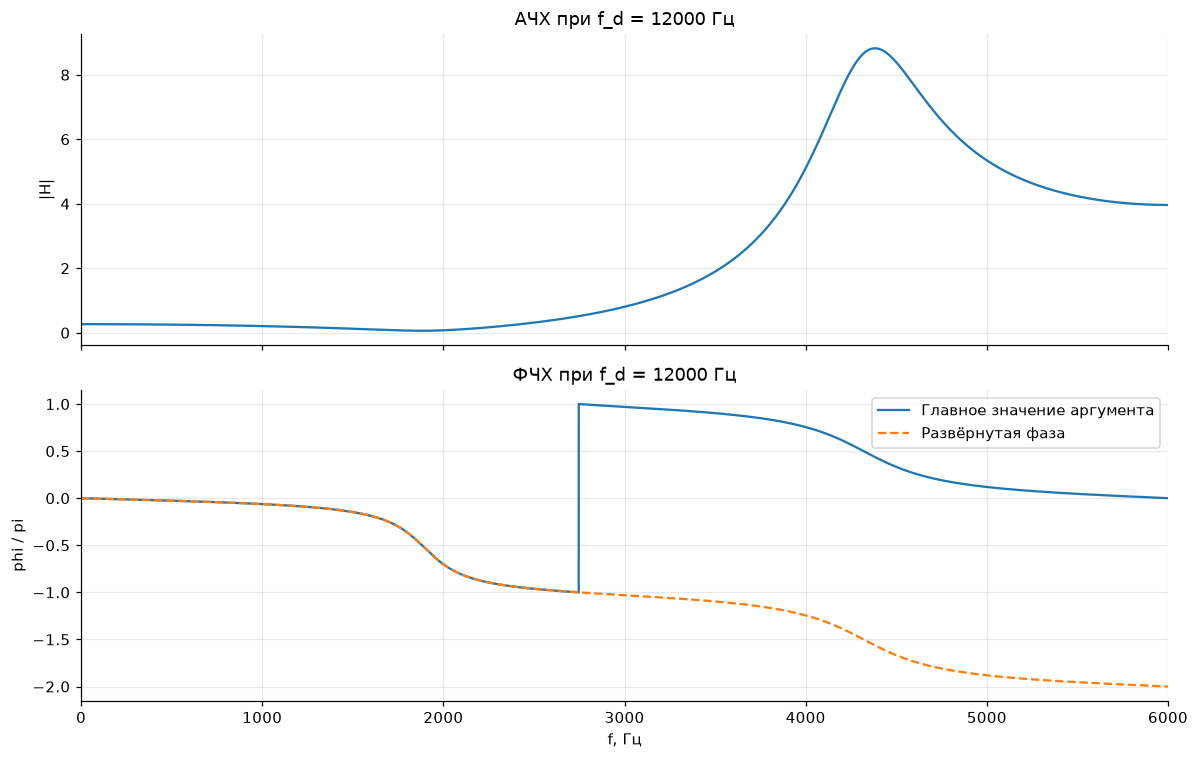

Провал АЧХ: 1881.226 Гц, резонанс: 4382.446 Гц.


In [16]:
f_sys = np.linspace(0, fd/2, 16385)
w_from_hz = 2*np.pi*f_sys/fd
H_hz = frequency_response(b, a, w_from_hz)
assert np.allclose(f_sys, w*fd/(2*np.pi))
assert np.allclose(H_hz, H)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(f_sys, np.abs(H_hz))
axes[0].set(title='АЧХ при f_d = 12000 Гц', ylabel='|H|')
axes[1].plot(f_sys, np.angle(H_hz)/np.pi, label='Главное значение аргумента')
axes[1].plot(f_sys, np.unwrap(np.angle(H_hz))/np.pi, '--', label='Развёрнутая фаза')
axes[1].set(title='ФЧХ при f_d = 12000 Гц', xlabel='f, Гц', ylabel='phi / pi', xlim=(0,fd/2))
axes[1].legend()
fig.tight_layout()
plt.show()
print(f'Провал АЧХ: {f_sys[i_min]:.3f} Гц, резонанс: {f_sys[i_max]:.3f} Гц.')


Изменение шкалы не меняет значений АЧХ и ФЧХ: изменяются только подписи и масштаб горизонтальной оси. Численное сопоставление прямых вычислений частотной характеристики в двух шкалах подтверждает это для всей сетки.

### Часть 2

#### Параметры
Во второй части частота дискретизации вычисляется по другой формуле и равна **6000 Гц**. Определим последовательность
$$
x(nT)=1.12\cos(2\pi\cdot750\,nT+\pi/4)
+2.24\cos(2\pi\cdot1125\,nT+\pi/8)
$$
Спектры ниже двусторонние, с центрированной частотной осью. Частотный шаг ДПФ равен $\Delta f=f_d/N=93.75$ Гц; гармоники попадают точно в отсчёты $k_1=8$ и $k_2=12$, поэтому спектральной утечки на данной сетке нет.


In [17]:
N = 64
fd_sig = 2000 * (Nvar % 5 + 1)
T = 1/fd_sig
A1 = 1 + 0.01*Nvar
A2 = 2*A1
f1 = fd_sig/8
f2 = 1.5*f1
phi1, phi2 = np.pi/4, np.pi/8
n = np.arange(N)
t_samples = n*T
x = A1*np.cos(2*np.pi*f1*t_samples+phi1) + A2*np.cos(2*np.pi*f2*t_samples+phi2)

| Параметр | Значение |
| :--- | :--- |
| $N$ | 64 |
| $f_d$, Гц | 6000 |
| $T$, с | 0.000166666667 |
| $A_1; A_2$ | 1.12; 2.24 |
| $f_1; f_2$, Гц | 750; 1125 |
| Начальные фазы | $\pi/4; \pi/8$ |
| $\Delta f$, Гц | 93.75 |
| $NT$, с | 0.010666667 |
| $(N-1)T$, с | 0.010500000 |

#### 1. Последовательность во временных шкалах

Дискретное время - это физические моменты $t_n=nT$ в секундах.
Дискретное нормированное время $\hat t_n=t_n/T=n$ безразмерно.
Графики различаются только масштабом горизонтальной оси.

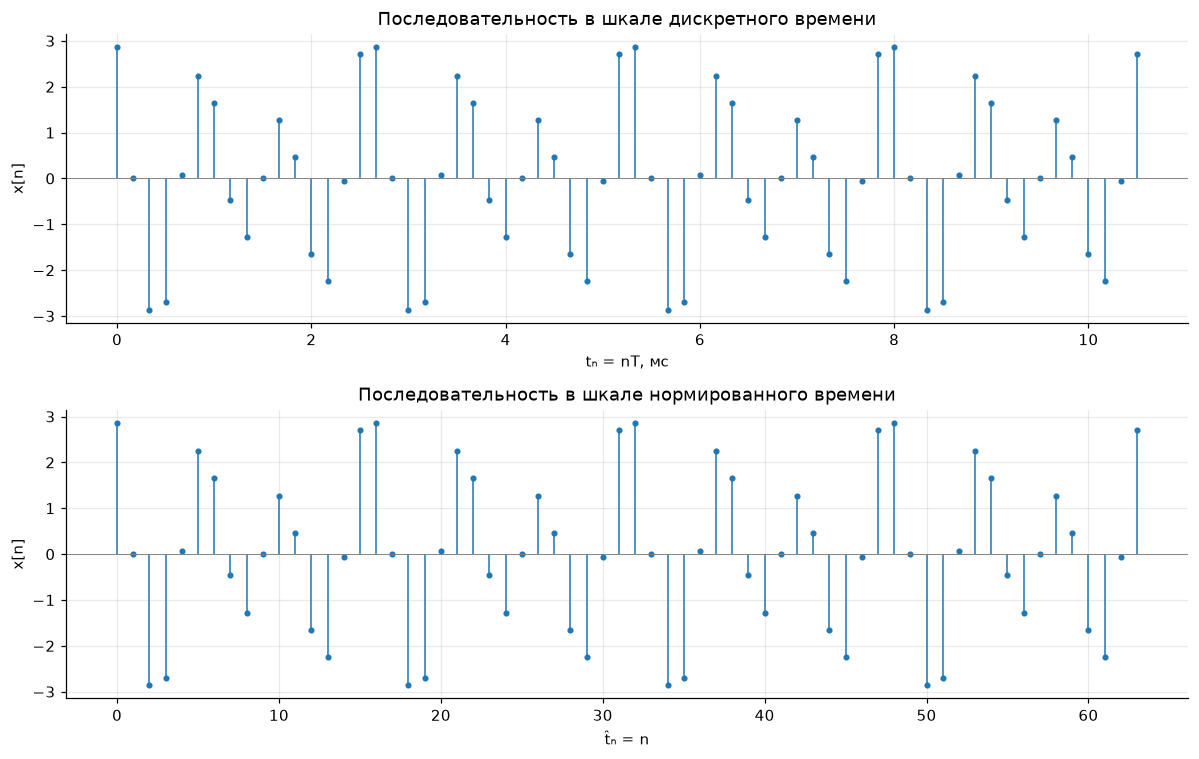

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
stem(axes[0], t_samples*1000, x, 'Последовательность в шкале дискретного времени', 'tₙ = nT, мс', 'x[n]')
stem(axes[1], n, x, 'Последовательность в шкале нормированного времени', 't̂ₙ = n', 'x[n]')
fig.tight_layout()
plt.show()

#### 2. ОДПФ от ДПФ

Вычислим $X[k]=\operatorname{DFT}\{x[n]\}$ и $x_{\mathrm{IDFT}}[n]=\operatorname{IDFT}\{X[k]\}$. Мнимая часть восстановленной последовательности должна равняться нулю с точностью округления.

Максимальная ошибка ОДПФ: 8.882e-16
Максимальная мнимая часть: 3.331e-16


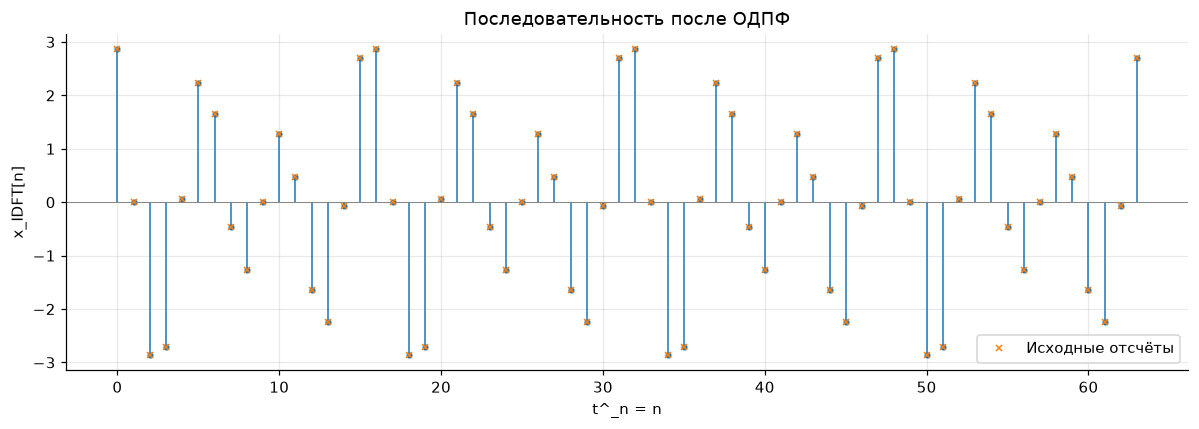

In [20]:
X = np.fft.fft(x)
x_idft = np.fft.ifft(X)
err_idft = np.max(np.abs(x_idft-x))
print(f'Максимальная ошибка ОДПФ: {err_idft:.3e}')
print(f'Максимальная мнимая часть: {np.max(np.abs(x_idft.imag)):.3e}')
fig, ax = plt.subplots()
stem(ax, n, x_idft.real, 'Последовательность после ОДПФ', 't^_n = n', 'x_IDFT[n]')
ax.plot(n, x, 'x', ms=4, label='Исходные отсчёты')
ax.legend()
fig.tight_layout()
plt.show()

ОДПФ возвращает исходную последовательность. Совпадение следует из взаимной обратимости выбранной пары преобразований, существующие расхождения являются допустимой погрешностью.

#### 3. Амплитудный и фазовый спектры
Каждая косинусоида представляется парой комплексных экспонент:
$$
A\cos(2\pi ft+\phi)=\frac A2e^{j\phi}e^{j2\pi ft}
+\frac A2e^{-j\phi}e^{-j2\pi ft}.
$$
Поэтому ожидаются линии амплитуды $A_1/2=0.56$ на $\pm750$ Гц и $A_2/2=1.12$ на $\pm1125$ Гц. Фазы на положительных частотах равны $\pi/4$ и $\pi/8$, на отрицательных $-\pi/4$ и $-\pi/8$. Чтобы не изображать фазы численного шума, фазовый график строится только для ненулевых спектральных линий с относительным порогом $10^{-10}$.

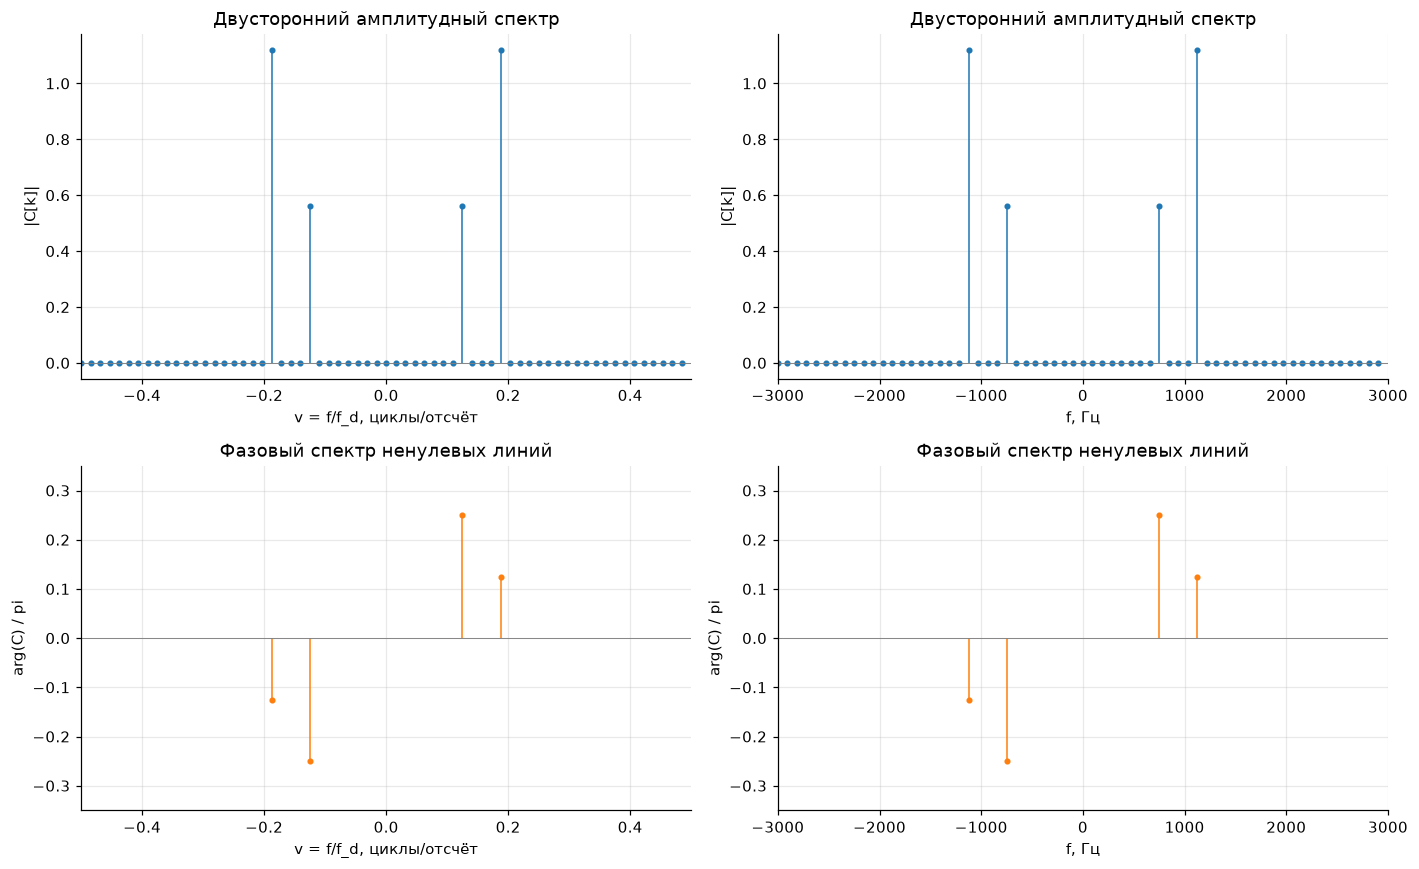

In [23]:
C = X/N
freq = np.fft.fftshift(np.fft.fftfreq(N, d=T))
nu = freq/fd_sig
omega_norm = 2*np.pi*nu
X_shift = np.fft.fftshift(X)
C_shift = X_shift/N
spectrum_amp = np.abs(C_shift)
active = spectrum_amp > spectrum_amp.max()*1e-10
spectrum_phase = np.angle(C_shift)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
stem(axes[0,0], nu, spectrum_amp, 'Двусторонний амплитудный спектр', 'v = f/f_d, циклы/отсчёт', '|C[k]|')
stem(axes[1,0], nu[active], spectrum_phase[active]/np.pi, 'Фазовый спектр ненулевых линий', 'v = f/f_d, циклы/отсчёт', 'arg(C) / pi', color='C1')
stem(axes[0,1], freq, spectrum_amp, 'Двусторонний амплитудный спектр', 'f, Гц', '|C[k]|')
stem(axes[1,1], freq[active], spectrum_phase[active]/np.pi, 'Фазовый спектр ненулевых линий', 'f, Гц', 'arg(C) / pi', color='C1')
for ax in axes[:,0]:
    ax.set_xlim(-0.5, 0.5)
for ax in axes[:,1]:
    ax.set_xlim(-fd_sig/2, fd_sig/2)
for ax in axes[1,:]:
    ax.set_ylim(-0.35, 0.35)
fig.tight_layout()
plt.show()

| $k$ | $\nu=k/N$ | $\hat{\omega}/\pi$ | $f$, Гц | $\lvert X[k]\rvert$ | $\lvert C[k]\rvert$ | Фаза / $\pi$ |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| -12 | -0.187500 | -0.375000 | -1125 | 71.680000 | 1.120000 | -0.125000 |
| -8 | -0.125000 | -0.250000 | -750 | 35.840000 | 0.560000 | -0.250000 |
| 8 | 0.125000 | 0.250000 | 750 | 35.840000 | 0.560000 | 0.250000 |
| 12 | 0.187500 | 0.375000 | 1125 | 71.680000 | 1.120000 | 0.125000 |

Связь частотных шкал: $\nu=f/f_d$, $\hat\omega=2\pi\nu$ на сетке ДПФ $\nu_k=k/N$. Для двух гармоник положительные нормированные частоты равны $1/8=0.125$ и $3/16=0.1875$ циклов/отсчёт, или $\pi/4$ и $3\pi/8$ рад/отсчёт. Основная центрированная полоса соответствует $\nu\in[-0.5;0.5)$ и $f\in[-3000;3000)$ Гц.

Спектр содержит только четыре ненулевые линии: обе частоты согласованы с сеткой ДПФ. Амплитудный спектр чётен, фазовый спектр ненулевых линий нечётен, что соответствует вещественности $x[n]$. В одностороннем спектре положительным гармоникам соответствовали бы амплитуды 1.12 и 2.24.

#### 4. ДПФ конечной и спектр периодической последовательностей
Рассмотрим те же 64 числа сначала как конечную последовательность, равную нулю вне блока, а затем как один период бесконечного периодического продолжения. Прямое ДПФ конечного блока даёт те же отсчёты $X[k]$. Для дополнительной проверки вычислим ДПФ по определению, без алгоритма БПФ.

Максимальное расхождение прямого ДПФ и FFT: 5.024e-13


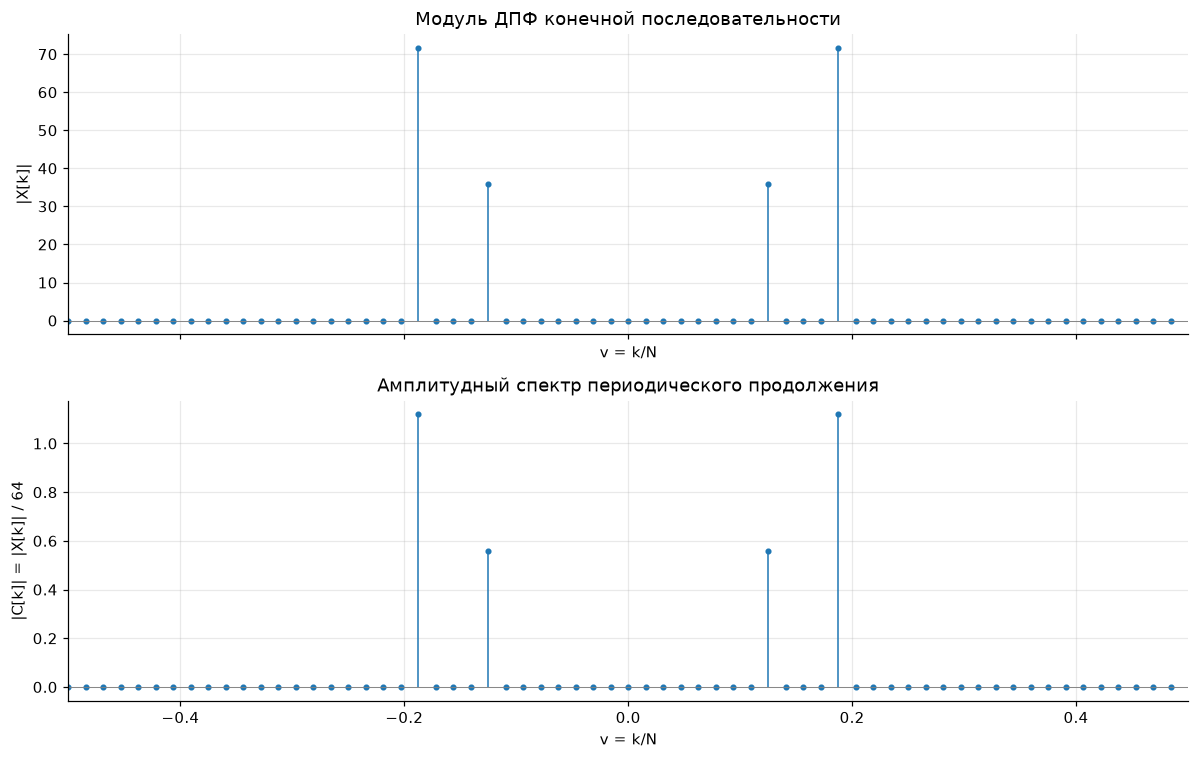

In [25]:
k = np.arange(N)
dft_matrix = np.exp(-2j*np.pi*np.outer(k, n)/N)
X_finite = dft_matrix @ x
print(f'Максимальное расхождение прямого ДПФ и FFT: {np.max(np.abs(X_finite-X)):.3e}')

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
stem(axes[0], nu, np.abs(np.fft.fftshift(X_finite)), 'Модуль ДПФ конечной последовательности', 'v = k/N', '|X[k]|')
stem(axes[1], nu, spectrum_amp, 'Амплитудный спектр периодического продолжения', 'v = k/N', '|C[k]| = |X[k]| / 64')
axes[1].set_xlim(-0.5, 0.5)
fig.tight_layout()
plt.show()


Положения ненулевых линий совпадают, а модули ДПФ больше амплитуд двустороннего спектра периодического продолжения в $N=64$ раза:
$$
|X[k]|=N|C[k]|.
$$
На частотах $\pm 750$ Гц модуль ДПФ равен $64\cdot 0.56=35.84$, на $\pm 1125$ Гц — $64\cdot 1.12=71.68$. Это различие нормировки, а не изменение сигнала.

У конечной последовательности преобразование Фурье дискретного времени является непрерывной периодической функцией частоты, ДПФ даёт только $N$ её отсчётов. У периодического продолжения спектр линейчатый, поэтому совпадение значений на сетке ДПФ не означает тождественности спектров конечного и бесконечного периодического сигналов на всех частотах.

#### 5. Восстановление периодического аналогового сигнала
Используем ровно заданное в условии центрированное суммирование:
$$
x(t)=\frac1N\sum_{k=-N/2}^{N/2-1}
\;
X_a[k]
\exp\left(j\frac{2\pi}{NT}kt\right),
$$

$$
X_a[k]=\begin{cases}
X[N+k],&-N/2\le k\le-1,\\
X[k],&0\le k\le N/2-1.
\end{cases}
$$

В данном случае отсчёт Найквиста $X[32]$ равен нулю с точностью округления, поэтому неоднозначность представления этой граничной гармоники на результат не влияет. Сетка времени: $t=0,0.25T,0.50T,\ldots,63T$ — всего $4(N-1)+1=253$ точки, обе границы включены.


In [26]:
k_centered = np.arange(-N//2, N//2)
# Для отрицательных k индексы N+k, для неотрицательных — k.
indices_Xa = np.where(k_centered < 0, N+k_centered, k_centered)
Xa = X[indices_Xa]
assert np.allclose(Xa, np.fft.fftshift(X))

t_fine = np.arange(4*(N-1)+1)*(0.25*T)
reconstruction_matrix = np.exp(2j*np.pi*np.outer(t_fine, k_centered)/(N*T))
x_rec_complex = reconstruction_matrix @ Xa / N
x_rec = x_rec_complex.real
x_original = A1*np.cos(2*np.pi*f1*t_fine+phi1) + A2*np.cos(2*np.pi*f2*t_fine+phi2)
err_reconstruction = np.max(np.abs(x_rec_complex-x_original))
err_nodes = np.max(np.abs(x_rec[::4]-x))
print(f'Точек сетки восстановления: {len(t_fine)}')
print(f'Шаг времени: {0.25*T:.12f} с')
print(f'Конец интервала: {t_fine[-1]:.9f} с')
print(f'Модуль отсчёта Найквиста: {abs(X[N//2]):.3e}')
print(f'Максимальная мнимая часть: {np.max(np.abs(x_rec_complex.imag)):.3e}')
print(f'Ошибка относительно исходной формулы: {err_reconstruction:.3e}')
print(f'Ошибка в исходных узлах: {err_nodes:.3e}')

Точек сетки восстановления: 253
Шаг времени: 0.000041666667 с
Конец интервала: 0.010500000 с
Модуль отсчёта Найквиста: 4.313e-14
Максимальная мнимая часть: 9.046e-16
Ошибка относительно исходной формулы: 3.543e-14
Ошибка в исходных узлах: 3.543e-14


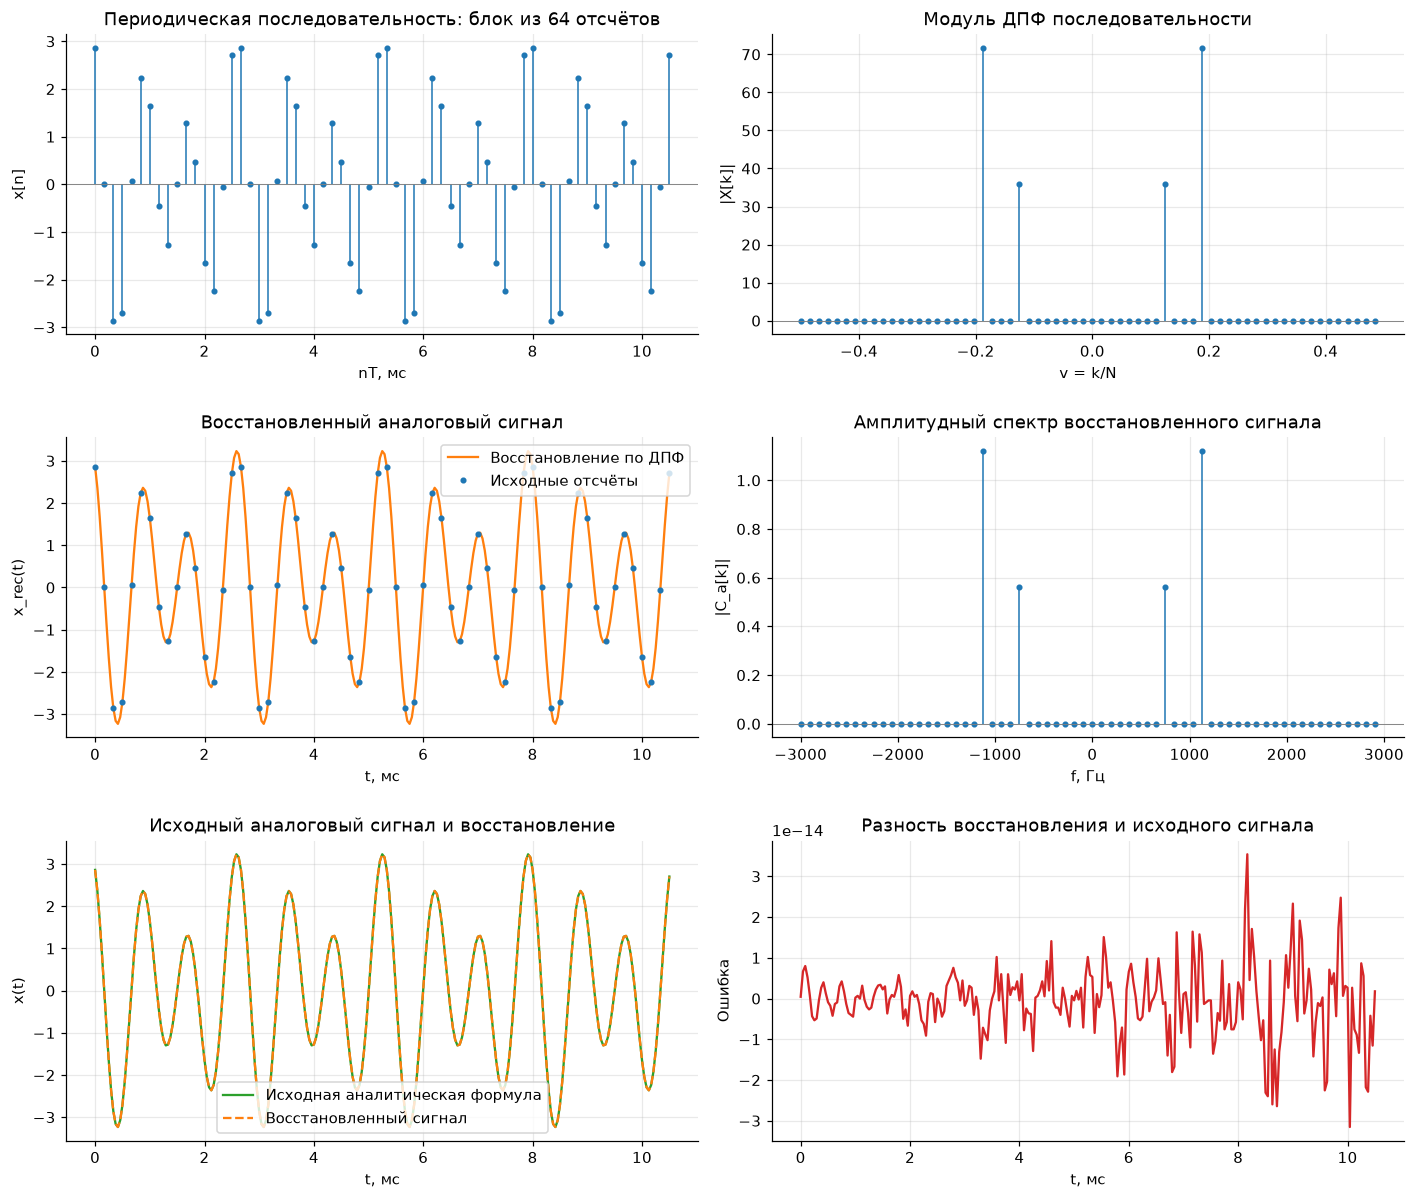

In [27]:
# Спектр аналогового тригонометрического полинома берём из коэффициентов
# ряда Фурье, а не из FFT укороченного интервала 0…(N−1)T.
analog_freq = k_centered/(N*T)
analog_coeff = Xa/N
analog_active = np.abs(analog_coeff) > np.abs(analog_coeff).max()*1e-10

fig, axes = plt.subplots(3, 2, figsize=(13, 11))
stem(axes[0,0], t_samples*1000, x, 'Периодическая последовательность: блок из 64 отсчётов', 'nT, мс', 'x[n]')
stem(axes[0,1], nu, np.abs(X_shift), 'Модуль ДПФ последовательности', 'v = k/N', '|X[k]|')
axes[1,0].plot(t_fine*1000, x_rec, color='C1', label='Восстановление по ДПФ')
axes[1,0].plot(t_samples*1000, x, 'o', ms=3, color='C0', label='Исходные отсчёты')
axes[1,0].set(title='Восстановленный аналоговый сигнал', xlabel='t, мс', ylabel='x_rec(t)')
axes[1,0].legend()
stem(axes[1,1], analog_freq, np.abs(analog_coeff), 'Амплитудный спектр восстановленного сигнала', 'f, Гц', '|C_a[k]|')
axes[2,0].plot(t_fine*1000, x_original, color='C2', label='Исходная аналитическая формула')
axes[2,0].plot(t_fine*1000, x_rec, '--', color='C1', label='Восстановленный сигнал')
axes[2,0].set(title='Исходный аналоговый сигнал и восстановление', xlabel='t, мс', ylabel='x(t)')
axes[2,0].legend()
axes[2,1].plot(t_fine*1000, x_rec-x_original, color='C3')
axes[2,1].set(title='Разность восстановления и исходного сигнала', xlabel='t, мс', ylabel='Ошибка')
fig.tight_layout()
plt.show()

| $f$, Гц | Модуль ДПФ | Амплитуда аналоговой линии | Фаза / $\pi$ |
| :--- | :--- | :--- | :--- |
| -1125 | 71.680000 | 1.120000 | -0.125000 |
| -750 | 35.840000 | 0.560000 | -0.250000 |
| 750 | 35.840000 | 0.560000 | 0.250000 |
| 1125 | 71.680000 | 1.120000 | 0.125000 |

#### 6. Анализ восстановления и связи спектров

Из формулы восстановления следует, что комплексная амплитуда аналоговой спектральной линии на частоте $f_k=k/(NT)$ равна $C_a[k]=X_a[k]/N$. Поэтому линии двустороннего аналогового спектра имеют амплитуды $0.56$ и $1.12$, а модули соответствующих отсчётов ДПФ: $35.84$ и $71.68$. Это коэффициенты ряда Фурье периодического сигнала, в его непрерывном преобразовании Фурье им соответствуют дельта-линии с этими весами при использовании частоты в Гц.

Отрицательные частоты во второй половине массива ДПФ необходимо перенести в отрицательную область перед восстановлением между узлами. На самих целочисленных узлах экспоненты с индексами $k$ и $k+N$ совпадают.

Восстановленный и исходный аналоговые сигналы визуально совпадают, а численная разность находится на уровне погрешности вычислений. Обе исходные частоты, 750 и 1125 Гц, меньше частоты Найквиста 3000 Гц и точно попадают в сетку $f_d/N$. Поэтому нет наложения спектров и центрированный ряд ДПФ содержит именно гармоники исходной формулы.

Амплитудный спектр восстановленного сигнала вычислен по коэффициентам этого ряда. Применение FFT непосредственно к 253 точкам на отрезке $[0;(N-1)T]$ задавало бы другой период продолжения и не являлось бы точным вычислением спектра построенного периодического полинома.


#### 7. Равенство Парсеваля
Проверим равенство сумм квадратов во временной и частотной областях:
$$
E_t=\sum_{n=0}^{63}|x[n]|^2,\qquad
E_f=\frac1{64}\sum_{k=0}^{63}|X[k]|^2.
$$
Средний квадрат за блок должен также совпадать с суммой квадратов модулей коэффициентов ряда Фурье и с аналитическим результатом:
$$
P=\frac{E_t}{N}=\sum_k|C[k]|^2
=\frac{A_1^2+A_2^2}{2}
=3.136.
$$

In [28]:
E_time = np.sum(np.abs(x)**2)
E_freq = np.sum(np.abs(X)**2)/N
P_time = E_time/N
P_spectrum = np.sum(np.abs(C)**2)
P_formula = (A1**2+A2**2)/2
parseval_abs = abs(E_time-E_freq)
parseval_rel = parseval_abs/E_time

assert np.isclose(E_time, E_freq, rtol=1e-12, atol=1e-12)
assert np.isclose(P_time, P_spectrum, atol=1e-12)
assert np.isclose(P_time, P_formula, atol=1e-12)
print('Равенство Парсеваля выполнено с точностью машинного округления.')

Равенство Парсеваля выполнено с точностью машинного округления.


| Величина | Значение |
| :--- | :--- |
| $\sum_{n=0}^{N-1}\lvert x[n]\rvert^2$ | 200.704000000000 |
| $\frac{1}{N}\sum_{k=0}^{N-1}\lvert X[k]\rvert^2$ | 200.704000000000 |
| Абсолютное расхождение | 5.684e-14 |
| Относительное расхождение | 2.832e-16 |
| $\frac{1}{N}\sum_{n=0}^{N-1}\lvert x[n]\rvert^2$ | 3.136000000000 |
| $\sum_{k=0}^{N-1}\lvert C[k]\rvert^2$ | 3.136000000000 |
| $\frac{A_1^2+A_2^2}{2}$ | 3.136000000000 |

Результат: $E_t=E_f=200.704$, средний квадрат $P=3.136$. ДПФ сохраняет сумму квадратов после учёта множителя нормировки $1/N$: один и тот же сигнал можно описывать через отсчёты времени или через частотные составляющие без потери этой величины. Гармоники ортогональны на выбранном блоке, поэтому их средние квадраты складываются независимо от начальных фаз.

Число $200.704$ - это сумма квадратов за один блок из 64 отсчётов. У ненулевого бесконечного периодического сигнала полная энергия бесконечна, а конечной характеристикой служит средняя мощность (средний квадрат) 3.136. Физическая энергия зависит от единиц сигнала и при переходе к интегралу по времени дополнительно учитывает шаг $T$.

## Выводы
В ходе лабораторной работы была вычислена импульсная характеристика рекурсивного звена и проверена её аналитическая формула. Полученная характеристика представляет собой бесконечную затухающую последовательность, для которой рассчитаны первые 22 отсчёта. Модули полюсов равны 0.843800924 и меньше единицы, поэтому причинное звено устойчиво.

Реакция на прямоугольный импульс была найдена двумя способами: по формуле свёртки и по разностному уравнению. Входной массив содержит 32 отсчёта, из которых 16 ненулевые. Полная свёртка массивов длины 22 и 32 содержит 53 отсчёта, однако её ненулевая часть занимает 37 отсчётов. Ограничение результата длиной входа задаёт интервал наблюдения и отбрасывает часть хвоста реакции. Использование только 22 отсчётов импульсной характеристики приводит к максимальному расхождению методов около $0.035218447$ на первых 32 отсчётах выхода. При увеличении длины импульсной характеристики до 32 отсчётов результаты на этом интервале совпадают с машинной точностью.

Анализ частотных характеристик показал соответствие между расположением нулей и полюсов и формой АЧХ. Нули обусловливают провал вблизи $0.3135\pi$, а полюсы резонансный максимум вблизи $0.7304\pi$. Низкочастотная область подавляется относительно высокочастотной. Наблюдаемый скачок главного значения фазы на $2\pi$ связан с выбором ветви аргумента и не сопровождается обращением АЧХ в ноль.

Во второй части работы получены четыре спектральные линии на частотах $\pm 750$ и $\pm 1125$ Гц с двусторонними амплитудами 0.56 и 1.12 соответственно. Модули соответствующих отсчётов ДПФ превышают эти амплитуды в 64 раза, что обусловлено принятой нормировкой преобразования. Обратное ДПФ восстанавливает исходную последовательность с машинной точностью.

По центрированным отсчётам ДПФ восстановлен исходный аналоговый сигнал на временной сетке с шагом $0.25T$. Равенство Парсеваля выполнено: сумма квадратов отсчётов за блок равна $200.704$, а средний квадрат $3.136$. Это подтверждает согласованность временного и частотного представлений сигнала.